# Notebook 16 — Ablations, Error Analysis and Robustness Checks

**Project:** Report-Guided Weak Supervision for Multi-Label Knee MRI Abnormality Detection

This notebook follows the project plan's ablation matrix and uses the actual **Notebook 12 hierarchical model**, not the earlier Notebook 11 series-only model. It reads the training-study labels and DINOv2 cache, preserves Notebook 09's five study-level folds, consumes Notebook 12 OOF predictions/checkpoints, and optionally compares the three supervision modes from Notebook 13 plus the statistical summary from Notebook 14.

### What is implemented
- **Error analysis:** study- and finding-level TP/FP/FN/TN taxonomy from held-out OOF predictions.
- **Pooling ablations:** learned slice attention vs mean slice pooling; learned series attention vs mean series pooling; and mean/mean pooling. Each variant is retrained on the same outer-training studies and evaluated once on the same held-out fold.
- **Supervision comparison:** Notebook 12 gold-only OOF vs the three Notebook 13 OOF modes.
- **Robustness:** controlled embedding noise and random 10% 2.5D-instance removal on held-out OOF folds.

The pooling ablations reuse the per-fold `best_epoch` selected by Notebook 12 as a fixed training budget. This avoids selecting epochs on the ablation's held-out fold and makes the comparison more controlled, but it does not claim that each ablation has independently optimized hyperparameters. Since the cache contains 2.5D instances, a separate 2D-vs-2.5D ablation cannot be done from these files alone.

### Attach through Kaggle “Add Input”
1. RSNA dataset (`train.csv`).
2. Notebook 09 **gold-scope** embeddings and metadata.
3. Notebook 12 output (OOF predictions, fold-training summary, five checkpoints).
4. Notebook 13 output (`oof_predictions_all_modes.csv`) — optional but recommended.
5. Notebook 14 output (`overall_metrics.csv`, `paired_bootstrap_differences.csv`) — optional reference.

## 1. Imports, configuration and artifact discovery

In [11]:
import os, gc, json, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_score, recall_score, hamming_loss
warnings.filterwarnings("ignore")

SEED=42; N_FOLDS=5; EMBED_DIM=384; NUM_CLASSES=12; ATTENTION_DIM=128; HIDDEN_DIM=128; DROPOUT=0.25
THRESHOLD=0.50; WEIGHT_DECAY=1e-4; LEARNING_RATE=1e-3; MAX_GRAD_NORM=1.0; POS_WEIGHT_MAX=20.0
RUN_POOLING_ABLATIONS=True
NOISE_FRACTION=0.05
RANDOM_INSTANCE_DROP_FRACTION=0.10
OUTPUT_DIR=Path("/kaggle/working/16_ablation_error"); OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
DEVICE=torch.device("cuda" if torch.cuda.is_available() else "cpu")
LABEL_COLS=["ACL","MCL","Medial Meniscus","Lateral Meniscus","Medial OA","Lateral OA","PF OA","Effusion","Synovitis","Baker's","Contusion","Fracture"]

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
seed_everything()
if torch.get_num_threads()>4: torch.set_num_threads(4)
print("Device:",DEVICE,"| pooling retraining:",RUN_POOLING_ABLATIONS)

Device: cpu | pooling retraining: True


## 2. Find the dataset and previous notebook outputs

In [12]:
SEARCH_ROOTS=["/kaggle/input","/kaggle/working"]
PRUNE_DIRS={"train_images","test_images","train_series","test_series","__pycache__",".git",".ipynb_checkpoints"}
def find_files(filename):
    hits=[]
    for root in SEARCH_ROOTS:
        if not os.path.exists(root): continue
        for current,dirs,files in os.walk(root):
            dirs[:]=[d for d in dirs if d not in PRUNE_DIRS]
            if filename in files: hits.append(os.path.join(current,filename))
    return sorted(set(hits),key=lambda p:(len(p),p))
def choose_file(filename,preferred=(),required=True,override=None):
    if override:
        if not os.path.isfile(override): raise FileNotFoundError(override)
        return override
    hits=find_files(filename)
    if not hits:
        if required: raise FileNotFoundError(f"Cannot find {filename}. Attach the correct Kaggle dataset / previous notebook output.")
        return None
    for token in preferred:
        sub=[p for p in hits if token.lower() in p.lower()]
        if sub: hits=sub; break
    if len(hits)>1: print(f"Multiple {filename} copies; using {hits[0]}")
    return hits[0]

TRAIN_CSV_PATH=choose_file("train.csv",("rsna-knee-abnormality-detection","rsna"))
EMBEDDING_PATH=choose_file("dinov2_vits14_embeddings_float16.npy",("09-dinov2","dinov2"))
METADATA_PATH=choose_file("dinov2_vits14_embedding_metadata.csv",("09-dinov2","dinov2"))
NB12_OOF_PATH=choose_file("oof_predictions.csv",("12_proposed_model",))
NB12_SUMMARY_PATH=choose_file("fold_training_summary.csv",("12_proposed_model",))
NB12_CHECKPOINTS={f:choose_file(f"hierarchical_dinov2_fold_{f}.pth",("12_proposed_model",)) for f in range(N_FOLDS)}
NB13_OOF_PATH=choose_file("oof_predictions_all_modes.csv",("13_weak_supervision","13"),required=False)
NB14_METRICS_PATH=choose_file("overall_metrics.csv",("14_evaluation","14"),required=False)
NB14_BOOTSTRAP_PATH=choose_file("paired_bootstrap_differences.csv",("14_evaluation","14"),required=False)
for k,v in [("dataset train.csv",TRAIN_CSV_PATH),("Notebook 09 embeddings",EMBEDDING_PATH),("Notebook 09 metadata",METADATA_PATH),("Notebook 12 OOF",NB12_OOF_PATH),("Notebook 12 fold summary",NB12_SUMMARY_PATH),("Notebook 13 OOF optional",NB13_OOF_PATH),("Notebook 14 metrics optional",NB14_METRICS_PATH)]: print(k,":",v)

dataset train.csv : /kaggle/input/competitions/rsna-knee-abnormality-detection/train.csv
Notebook 09 embeddings : /kaggle/input/notebooks/minnieg12/09-dinov2/dinov2_vits14_embeddings_float16.npy
Notebook 09 metadata : /kaggle/input/notebooks/minnieg12/09-dinov2/dinov2_vits14_embedding_metadata.csv
Notebook 12 OOF : /kaggle/input/notebooks/richashanbhag/12-proposed-model/12_proposed_model/oof_predictions.csv
Notebook 12 fold summary : /kaggle/input/notebooks/richashanbhag/12-proposed-model/12_proposed_model/fold_training_summary.csv
Notebook 13 OOF optional : /kaggle/input/notebooks/richashanbhag/13-weak-supervision/13_weak_supervision/oof_predictions_all_modes.csv
Notebook 14 metrics optional : /kaggle/input/notebooks/richashanbhag/14-evaluation/14_evaluation/overall_metrics.csv


## 3. Load gold labels, cached embeddings, folds and OOF predictions

No new folds are created. The outer-held-out assignments from Notebook 09 / Notebook 12 remain the common comparison protocol.

In [13]:
train=pd.read_csv(TRAIN_CSV_PATH); metadata=pd.read_csv(METADATA_PATH); embeddings=np.load(EMBEDDING_PATH,mmap_mode="r")
oof12=pd.read_csv(NB12_OOF_PATH); fold_summary=pd.read_csv(NB12_SUMMARY_PATH)
for df,name in [(train,"train"),(metadata,"metadata"),(oof12,"Notebook 12 OOF")]:
    if "StudyInstanceUID" not in df.columns: raise ValueError(f"{name} missing StudyInstanceUID")
    df["StudyInstanceUID"]=df["StudyInstanceUID"].astype(str)
for c in LABEL_COLS:
    if c not in train.columns: raise ValueError(f"train.csv missing {c}")
    train[c]=pd.to_numeric(train[c],errors="coerce")
gold=train.dropna(subset=LABEL_COLS).copy()
if gold["StudyInstanceUID"].duplicated().any(): raise ValueError("Duplicate gold study IDs.")
if len(gold)!=58: raise ValueError(f"Expected 58 gold studies; found {len(gold)}")
gold[LABEL_COLS]=gold[LABEL_COLS].astype(int); gold=gold.sort_values("StudyInstanceUID").reset_index(drop=True)
GOLD_IDS=gold["StudyInstanceUID"].tolist(); GOLD_ID_SET=set(GOLD_IDS)
if not {"Embedding_Index","SeriesInstanceUID"}.issubset(metadata.columns): raise ValueError("Notebook 09 metadata schema is incomplete.")
metadata["Embedding_Index"]=pd.to_numeric(metadata["Embedding_Index"],errors="raise").astype(int)
metadata["StudyInstanceUID"]=metadata["StudyInstanceUID"].astype(str); metadata["SeriesInstanceUID"]=metadata["SeriesInstanceUID"].astype(str)
metadata=metadata.sort_values("Embedding_Index").reset_index(drop=True)
if embeddings.ndim!=2 or embeddings.shape[1]!=EMBED_DIM or len(metadata)!=len(embeddings): raise ValueError("Embedding array/metadata shape mismatch.")
if not np.array_equal(metadata["Embedding_Index"].to_numpy(),np.arange(len(metadata))): raise ValueError("Embedding_Index must be contiguous from zero.")
if set(metadata["StudyInstanceUID"].unique())!=GOLD_ID_SET: raise ValueError("Notebook 09 embedding study IDs differ from gold train.csv studies.")

required={"StudyInstanceUID","fold"}
for c in LABEL_COLS: required.update({f"{c}_true",f"{c}_prob"})
miss=required-set(oof12.columns)
if miss: raise ValueError(f"Notebook 12 OOF missing columns: {sorted(miss)}")
oof12["fold"]=pd.to_numeric(oof12["fold"],errors="raise").astype(int)
counts=oof12["StudyInstanceUID"].value_counts()
if set(counts.index)!=GOLD_ID_SET or not (counts==1).all(): raise ValueError("Notebook 12 OOF coverage is not exactly one row per gold study.")
FOLD_BY_STUDY=oof12.set_index("StudyInstanceUID")["fold"].astype(int).to_dict()
if set(FOLD_BY_STUDY.values())!=set(range(N_FOLDS)): raise ValueError("Expected fold IDs 0..4.")
# Direct dictionary creation avoids relying on modified column attribute names.
LABEL_BY_STUDY={row["StudyInstanceUID"]:row[LABEL_COLS].to_numpy(dtype=np.float32) for _,row in gold.iterrows()}
STUDY_BAGS={}
for sid,g in metadata.groupby("StudyInstanceUID",sort=True):
    series=[]
    for ser,sg in g.groupby("SeriesInstanceUID",sort=True):
        idx=sg.sort_values("Embedding_Index")["Embedding_Index"].to_numpy(dtype=int)
        if len(idx): series.append(idx)
    if not series: raise ValueError(f"No DINOv2 instances for {sid}")
    STUDY_BAGS[sid]=series
if set(STUDY_BAGS)!=GOLD_ID_SET: raise ValueError("Nested series bags do not cover gold studies.")

def get_study_tensors(study_id,noise_std=0.0,drop_fraction=0.0,seed=SEED):
    result=[]; rng=np.random.RandomState(int(seed))
    for idx in STUDY_BAGS[str(study_id)]:
        arr=np.asarray(embeddings[idx],dtype=np.float32).copy()
        if noise_std>0: arr=arr+rng.normal(0.0,noise_std,size=arr.shape).astype(np.float32)
        if drop_fraction>0 and len(arr)>1:
            n_drop=min(len(arr)-1,int(round(len(arr)*drop_fraction)))
            if n_drop>0:
                remove=set(rng.choice(len(arr),size=n_drop,replace=False).tolist())
                keep=[j for j in range(len(arr)) if j not in remove]
                arr=arr[keep]
        result.append(torch.as_tensor(arr,dtype=torch.float32,device=DEVICE))
    return result

print("Gold studies:",len(GOLD_IDS),"| DINOv2 instances:",len(metadata),"| series:",sum(map(len,STUDY_BAGS.values())))
print("Fold sizes:",pd.Series(FOLD_BY_STUDY).value_counts().sort_index().to_dict())

Gold studies: 58 | DINOv2 instances: 10528 | series: 336
Fold sizes: {0: 12, 1: 12, 2: 12, 3: 11, 4: 11}


## 4. Error analysis from Notebook 12 held-out OOF predictions

Each row is a study-level prediction. Threshold is fixed at 0.50 to match the preceding notebooks; ROC-AUC and PR-AUC remain threshold-free.

In [14]:
prob_cols=[f"{c}_prob" for c in LABEL_COLS]
true_cols=[f"{c}_true" for c in LABEL_COLS]
P12=oof12.set_index("StudyInstanceUID").loc[GOLD_IDS,prob_cols].to_numpy(dtype=float)
Y=np.stack([LABEL_BY_STUDY[s] for s in GOLD_IDS]).astype(int)
Y12=oof12.set_index("StudyInstanceUID").loc[GOLD_IDS,true_cols].to_numpy(dtype=int)
if not np.array_equal(Y,Y12): raise ValueError("Notebook 12 OOF gold targets do not match train.csv.")
if not np.isfinite(P12).all() or ((P12<0)|(P12>1)).any(): raise ValueError("Invalid Notebook 12 probabilities.")
PRED12=(P12>=THRESHOLD).astype(int)

label_rows=[]; study_rows=[]
for i,sid in enumerate(GOLD_IDS):
    fp_labels=[]; fn_labels=[]; tp_labels=[]; tn_labels=[]
    for j,label in enumerate(LABEL_COLS):
        yt=int(Y[i,j]); yp=int(PRED12[i,j]); p=float(P12[i,j])
        typ="TP" if yt==1 and yp==1 else "FN" if yt==1 and yp==0 else "FP" if yt==0 and yp==1 else "TN"
        label_rows.append({"StudyInstanceUID":sid,"fold":int(FOLD_BY_STUDY[sid]),"finding":label,"true":yt,"probability":p,"predicted":yp,"error_type":typ,"confidence_from_threshold":float(abs(p-THRESHOLD)*2)})
        if typ=="FP": fp_labels.append(label)
        elif typ=="FN": fn_labels.append(label)
        elif typ=="TP": tp_labels.append(label)
        else: tn_labels.append(label)
    study_rows.append({"StudyInstanceUID":sid,"fold":int(FOLD_BY_STUDY[sid]),"n_FP":len(fp_labels),"n_FN":len(fn_labels),"n_TP":len(tp_labels),"n_TN":len(tn_labels),"n_errors":len(fp_labels)+len(fn_labels),"false_positive_findings":"; ".join(fp_labels),"false_negative_findings":"; ".join(fn_labels),"study_error_category":"no_errors" if not (fp_labels or fn_labels) else "false_negative_and_positive" if fp_labels and fn_labels else "false_negative_only" if fn_labels else "false_positive_only"})
label_errors=pd.DataFrame(label_rows); study_errors=pd.DataFrame(study_rows)
error_counts=label_errors.groupby(["finding","error_type"]).size().unstack(fill_value=0).reset_index()
label_errors.to_csv(OUTPUT_DIR/"16_label_level_error_taxonomy.csv",index=False)
study_errors.to_csv(OUTPUT_DIR/"16_study_error_summary.csv",index=False)
error_counts.to_csv(OUTPUT_DIR/"16_error_counts_by_label.csv",index=False)

per_label=[]
for j,label in enumerate(LABEL_COLS):
    yt=Y[:,j]; yp=PRED12[:,j]; pp=P12[:,j]
    per_label.append({"finding":label,"positive_support":int(yt.sum()),"negative_support":int((1-yt).sum()),"FP":int(((yt==0)&(yp==1)).sum()),"FN":int(((yt==1)&(yp==0)).sum()),"TP":int(((yt==1)&(yp==1)).sum()),"TN":int(((yt==0)&(yp==0)).sum()),"roc_auc":roc_auc_score(yt,pp) if len(np.unique(yt))==2 else np.nan,"pr_auc":average_precision_score(yt,pp) if len(np.unique(yt))==2 else np.nan,"f1":f1_score(yt,yp,zero_division=0)})
per_label_df=pd.DataFrame(per_label)
per_label_df.to_csv(OUTPUT_DIR/"16_oof_per_label_metrics.csv",index=False)
display(study_errors.sort_values("n_errors",ascending=False).head(10)); display(per_label_df)

,StudyInstanceUID,fold,n_FP,n_FN,n_TP,n_TN,n_errors,false_positive_findings,false_negative_findings,study_error_category
5,1.2.826.0.1.3680043.8.498.11548045715264151632...,0,5,3,0,4,8,ACL; Medial Meniscus; Medial OA; Lateral OA; P...,Effusion; Synovitis; Contusion,false_negative_and_positive
2,1.2.826.0.1.3680043.8.498.10306159113324811538...,3,4,4,0,4,8,ACL; Effusion; Contusion; Fracture,Medial Meniscus; Medial OA; PF OA; Synovitis,false_negative_and_positive
43,1.2.826.0.1.3680043.8.498.65708905118633339771...,3,1,7,1,3,8,Fracture,Medial Meniscus; Lateral Meniscus; Medial OA; ...,false_negative_and_positive
54,1.2.826.0.1.3680043.8.498.88077418639301174409...,1,0,8,1,3,8,,ACL; Medial Meniscus; Lateral Meniscus; Medial...,false_negative_only
9,1.2.826.0.1.3680043.8.498.11915937982684988073...,2,2,5,1,4,7,ACL; Contusion,Lateral Meniscus; Lateral OA; PF OA; Synovitis...,false_negative_and_positive
21,1.2.826.0.1.3680043.8.498.22109739962224309418...,3,3,4,0,5,7,ACL; Effusion; Fracture,Lateral Meniscus; Medial OA; Lateral OA; Baker's,false_negative_and_positive
18,1.2.826.0.1.3680043.8.498.16060119389060497136...,4,0,7,2,3,7,,Lateral Meniscus; Medial OA; Lateral OA; PF OA...,false_negative_only
28,1.2.826.0.1.3680043.8.498.32321830776739689645...,4,1,6,1,4,7,Medial Meniscus,ACL; MCL; PF OA; Synovitis; Contusion; Fracture,false_negative_and_positive
16,1.2.826.0.1.3680043.8.498.13335129881737731410...,2,0,7,2,3,7,,Medial Meniscus; Lateral Meniscus; Medial OA; ...,false_negative_only
13,1.2.826.0.1.3680043.8.498.12801308844398614687...,0,0,6,1,5,6,,Medial Meniscus; Lateral Meniscus; Medial OA; ...,false_negative_only


,finding,positive_support,negative_support,FP,FN,TP,TN,roc_auc,pr_auc,f1
0,ACL,24,34,16,13,11,18,0.502451,0.408814,0.431373
1,MCL,9,49,2,8,1,47,0.360544,0.175739,0.166667
2,Medial Meniscus,26,32,10,18,8,22,0.567308,0.525717,0.363636
3,Lateral Meniscus,23,35,0,21,2,35,0.587578,0.531975,0.160000
4,Medial OA,15,43,4,11,4,39,0.635659,0.464832,0.347826
5,Lateral OA,11,47,4,10,1,43,0.495164,0.197141,0.125000
6,PF OA,21,37,10,17,4,27,0.495495,0.351563,0.228571
7,Effusion,35,23,15,7,28,8,0.581366,0.679429,0.717949
8,Synovitis,27,31,4,26,1,27,0.508961,0.487224,0.062500
9,Baker's,12,46,0,12,0,46,0.414855,0.183514,0.000000


## 5. Compare gold-only and report-guided supervision modes

Notebook 13 supplies three OOF modes evaluated on the same five held-out folds. Notebook 14 is an optional independent evaluation summary. Do not mix the models' OOF rows or count them as additional studies.

In [15]:
def metric_summary(y_true, y_prob, model_name):
    y_pred = (y_prob >= THRESHOLD).astype(int)
    aucs, aps, f1s = [], [], []

    for j in range(y_true.shape[1]):
        yt = y_true[:, j]
        pp = y_prob[:, j]

        aucs.append(
            roc_auc_score(yt, pp)
            if len(np.unique(yt)) == 2 else np.nan
        )
        aps.append(
            average_precision_score(yt, pp)
            if len(np.unique(yt)) == 2 else np.nan
        )
        f1s.append(f1_score(yt, y_pred[:, j], zero_division=0))

    return {
        "model": model_name,
        "macro_roc_auc": float(np.nanmean(aucs)),
        "macro_pr_auc": float(np.nanmean(aps)),
        "macro_f1": float(np.mean(f1s)),
        "micro_f1": float(
            f1_score(y_true.ravel(), y_pred.ravel(), zero_division=0)
        ),
        "hamming_loss": float(hamming_loss(y_true, y_pred))
    }


comparison_rows = [
    metric_summary(Y, P12, "Notebook 12 — gold-only hierarchical MIL")
]

weak_oof = None

if NB13_OOF_PATH:
    weak_oof = pd.read_csv(NB13_OOF_PATH)

    weak_oof.columns = weak_oof.columns.astype(str).str.strip()
    weak_oof["StudyInstanceUID"] = (
        weak_oof["StudyInstanceUID"].astype(str)
    )

    required_weak = {"StudyInstanceUID", "fold", "mode"}

    for c in LABEL_COLS:
        required_weak.update({f"{c}_true", f"{c}_prob"})

    missing = required_weak - set(weak_oof.columns)

    if missing:
        raise ValueError(
            f"Notebook 13 OOF schema missing: {sorted(missing)}"
        )

    expected_modes = {
        "gold_only",
        "gold_plus_unweighted_weak",
        "gold_plus_confidence_weighted_weak"
    }

    actual_modes = set(weak_oof["mode"].dropna().unique())

    if actual_modes != expected_modes:
        raise ValueError(
            f"Unexpected Notebook 13 modes: {sorted(actual_modes)}"
        )

    for mode_name in sorted(expected_modes):

        # IMPORTANT: Use bracket notation for the mode column.
        mode_rows = weak_oof[
            weak_oof["mode"] == mode_name
        ].copy()

        mode_counts = mode_rows["StudyInstanceUID"].value_counts()

        if (
            set(mode_counts.index) != GOLD_ID_SET
            or not (mode_counts == 1).all()
        ):
            raise ValueError(
                f"Notebook 13 OOF coverage is not exactly "
                f"one row per gold study for {mode_name}."
            )

        mode_fold_map = (
            mode_rows.set_index("StudyInstanceUID")["fold"]
            .astype(int)
            .to_dict()
        )

        if mode_fold_map != FOLD_BY_STUDY:
            raise ValueError(
                f"Notebook 13 fold assignments differ "
                f"from Notebook 12 for {mode_name}."
            )

        part = mode_rows.set_index("StudyInstanceUID").loc[GOLD_IDS]

        if not np.array_equal(
            part[true_cols].to_numpy(dtype=int), Y
        ):
            raise ValueError(
                f"Notebook 13 gold truth mismatch for {mode_name}"
            )

        p = part[prob_cols].to_numpy(dtype=float)

        if not np.isfinite(p).all():
            raise ValueError(
                f"Non-finite probability in Notebook 13 mode {mode_name}"
            )

        comparison_rows.append(
            metric_summary(
                Y,
                p,
                f"Notebook 13 — {mode_name}"
            )
        )

    weak_oof.to_csv(
        OUTPUT_DIR / "16_notebook13_oof_reference_copy.csv",
        index=False
    )

else:
    print(
        "Notebook 13 OOF file not attached; "
        "supervision comparison will contain Notebook 12 only."
    )


if NB14_METRICS_PATH:
    nb14_metrics = pd.read_csv(NB14_METRICS_PATH)

    nb14_metrics.to_csv(
        OUTPUT_DIR / "16_notebook14_evaluation_reference.csv",
        index=False
    )

    print("Notebook 14 overall metrics loaded:", nb14_metrics.shape)


if NB14_BOOTSTRAP_PATH:
    nb14_boot = pd.read_csv(NB14_BOOTSTRAP_PATH)

    nb14_boot.to_csv(
        OUTPUT_DIR / "16_notebook14_paired_bootstrap_reference.csv",
        index=False
    )

    print("Notebook 14 paired bootstrap rows:", len(nb14_boot))


print("\nComparison rows successfully prepared:", len(comparison_rows))

Notebook 14 overall metrics loaded: (3, 11)
Notebook 14 paired bootstrap rows: 10

Comparison rows successfully prepared: 4


## 6. Define controlled hierarchical pooling variants

All variants keep the same cached DINOv2 2.5D embeddings, classifier, five folds and training budget. Only the slice- and/or series-level aggregation operator is changed.

In [16]:
class GatedAttentionPool(nn.Module):
    def __init__(self,input_dim=EMBED_DIM,attention_dim=ATTENTION_DIM):
        super().__init__(); self.norm=nn.LayerNorm(input_dim)
        self.attention_v=nn.Linear(input_dim,attention_dim); self.attention_u=nn.Linear(input_dim,attention_dim); self.attention_w=nn.Linear(attention_dim,1,bias=False)
    def forward(self,x):
        if x.ndim!=2 or x.shape[0]==0: raise ValueError("Expected non-empty [N,D] tensor")
        z=self.norm(x); gate=torch.tanh(self.attention_v(z))*torch.sigmoid(self.attention_u(z))
        weights=torch.softmax(self.attention_w(gate).squeeze(-1),dim=0)
        return (weights.unsqueeze(-1)*z).sum(0),weights

class HierarchicalMILVariant(nn.Module):
    def __init__(self,slice_pool="attention",series_pool="attention"):
        super().__init__(); self.slice_pool=slice_pool; self.series_pool=series_pool
        self.slice_attention=GatedAttentionPool(); self.series_attention=GatedAttentionPool()
        self.classifier=nn.Sequential(nn.LayerNorm(EMBED_DIM),nn.Linear(EMBED_DIM,HIDDEN_DIM),nn.GELU(),nn.Dropout(DROPOUT),nn.Linear(HIDDEN_DIM,NUM_CLASSES))
    def forward(self,series_bags):
        series_vectors=[]
        for x in series_bags:
            if self.slice_pool=="attention": pooled,_=self.slice_attention(x)
            elif self.slice_pool=="mean": pooled=x.mean(dim=0)
            else: raise ValueError(self.slice_pool)
            series_vectors.append(pooled)
        series_matrix=torch.stack(series_vectors,dim=0)
        if self.series_pool=="attention": study_vector,_=self.series_attention(series_matrix)
        elif self.series_pool=="mean": study_vector=series_matrix.mean(dim=0)
        else: raise ValueError(self.series_pool)
        return self.classifier(study_vector)

VARIANTS={
    "mean_slice_attention_series":{"slice_pool":"mean","series_pool":"attention"},
    "attention_slice_mean_series":{"slice_pool":"attention","series_pool":"mean"},
    "mean_slice_mean_series":{"slice_pool":"mean","series_pool":"mean"}
}

def pos_weight_for(ids):
    y=np.stack([LABEL_BY_STUDY[s] for s in ids]).astype(np.float32); pos=y.sum(0); neg=len(y)-pos
    w=np.ones(NUM_CLASSES,dtype=np.float32); mask=pos>0; w[mask]=neg[mask]/pos[mask]
    return torch.tensor(np.clip(w,1.0,POS_WEIGHT_MAX),dtype=torch.float32,device=DEVICE)

def train_one_epoch(model,ids,criterion,optimizer,fold,epoch,variant):
    model.train(); rng=np.random.RandomState(SEED+fold*10000+epoch+sum(map(ord,variant)))
    losses=[]
    for sid in rng.permutation(np.asarray(ids,dtype=object)):
        bags=get_study_tensors(str(sid),seed=SEED+fold+epoch)
        y=torch.as_tensor(LABEL_BY_STUDY[str(sid)],dtype=torch.float32,device=DEVICE)
        optimizer.zero_grad(set_to_none=True); logits=model(bags); loss=criterion(logits.unsqueeze(0),y.unsqueeze(0))
        if not torch.isfinite(loss): raise RuntimeError(f"Non-finite ablation loss: {variant}, fold={fold}")
        loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(),MAX_GRAD_NORM); optimizer.step(); losses.append(float(loss.item()))
    return float(np.mean(losses))

def predict_one(model,sid):
    model.eval()
    with torch.no_grad(): return torch.sigmoid(model(get_study_tensors(sid))).cpu().numpy()

summary_required={"fold","best_epoch"}
if summary_required-set(fold_summary.columns): raise ValueError("Notebook 12 fold_training_summary.csv must include fold and best_epoch.")
BEST_EPOCH={int(r.fold):int(r.best_epoch) for r in fold_summary.itertuples()}
if set(BEST_EPOCH)!=set(range(N_FOLDS)) or any(v<1 for v in BEST_EPOCH.values()): raise ValueError("Invalid best_epoch values in Notebook 12 fold summary.")
print("Fixed fold training budgets from Notebook 12:",BEST_EPOCH)

Fixed fold training budgets from Notebook 12: {0: 6, 1: 3, 2: 1, 3: 2, 4: 7}


## 7. Retrain the pooling ablations on the preserved folds

The outer held-out fold is excluded from every ablation fit. The fold's epoch count is transferred from Notebook 12's inner-validation selection and is fixed before the ablation's held-out prediction is generated.

In [17]:
abl_pred_rows=[]
if RUN_POOLING_ABLATIONS:
    for variant,settings in VARIANTS.items():
        print("\n=== Ablation:",variant,"===")
        for fold in range(N_FOLDS):
            outer_train=sorted([s for s in GOLD_IDS if FOLD_BY_STUDY[s]!=fold])
            outer_test=sorted([s for s in GOLD_IDS if FOLD_BY_STUDY[s]==fold])
            seed_everything(SEED+10000*fold+sum(map(ord,variant)))
            model=HierarchicalMILVariant(**settings).to(DEVICE)
            criterion=nn.BCEWithLogitsLoss(pos_weight=pos_weight_for(outer_train))
            optimizer=torch.optim.AdamW(model.parameters(),lr=LEARNING_RATE,weight_decay=WEIGHT_DECAY)
            n_epochs=BEST_EPOCH[fold]
            for epoch in range(1,n_epochs+1):
                loss=train_one_epoch(model,outer_train,criterion,optimizer,fold,epoch,variant)
                if epoch==1 or epoch==n_epochs or epoch%5==0: print(f"fold={fold} epoch={epoch}/{n_epochs} loss={loss:.4f}")
            fold_path=OUTPUT_DIR/f"{variant}_fold_{fold}.pth"
            torch.save({"variant":variant,"fold":fold,"slice_pool":settings["slice_pool"],"series_pool":settings["series_pool"],"model_state_dict":model.state_dict(),"label_cols":LABEL_COLS,"best_epoch_from_notebook12":n_epochs},fold_path)
            for sid in outer_test:
                probs=predict_one(model,sid); row={"StudyInstanceUID":sid,"fold":fold,"variant":variant}
                for j,c in enumerate(LABEL_COLS): row[f"{c}_true"]=int(LABEL_BY_STUDY[sid][j]); row[f"{c}_prob"]=float(probs[j])
                abl_pred_rows.append(row)
            del model,optimizer,criterion; gc.collect()
            if torch.cuda.is_available(): torch.cuda.empty_cache()
    ablation_predictions=pd.DataFrame(abl_pred_rows)
    ablation_predictions.to_csv(OUTPUT_DIR/"16_pooling_ablation_oof_predictions.csv",index=False)
else:
    ablation_predictions=pd.DataFrame()
    print("RUN_POOLING_ABLATIONS=False: retraining skipped by configuration.")


=== Ablation: mean_slice_attention_series ===
fold=0 epoch=1/6 loss=0.9505
fold=0 epoch=5/6 loss=0.8753
fold=0 epoch=6/6 loss=0.8585
fold=1 epoch=1/3 loss=1.0213
fold=1 epoch=3/3 loss=0.9631
fold=2 epoch=1/1 loss=1.0104
fold=3 epoch=1/2 loss=1.0206
fold=3 epoch=2/2 loss=0.9503
fold=4 epoch=1/7 loss=1.0085
fold=4 epoch=5/7 loss=0.9647
fold=4 epoch=7/7 loss=0.8302

=== Ablation: attention_slice_mean_series ===
fold=0 epoch=1/6 loss=0.9488
fold=0 epoch=5/6 loss=0.8765
fold=0 epoch=6/6 loss=0.8566
fold=1 epoch=1/3 loss=1.0189
fold=1 epoch=3/3 loss=0.9626
fold=2 epoch=1/1 loss=1.0091
fold=3 epoch=1/2 loss=1.0191
fold=3 epoch=2/2 loss=0.9493
fold=4 epoch=1/7 loss=1.0083
fold=4 epoch=5/7 loss=0.9067
fold=4 epoch=7/7 loss=0.7890

=== Ablation: mean_slice_mean_series ===
fold=0 epoch=1/6 loss=0.9242
fold=0 epoch=5/6 loss=0.9150
fold=0 epoch=6/6 loss=0.8814
fold=1 epoch=1/3 loss=1.0510
fold=1 epoch=3/3 loss=0.9850
fold=2 epoch=1/1 loss=1.0000
fold=3 epoch=1/2 loss=1.0007
fold=3 epoch=2/2 loss=0

## 8. Score ablations and compare with the main/weak-supervision models

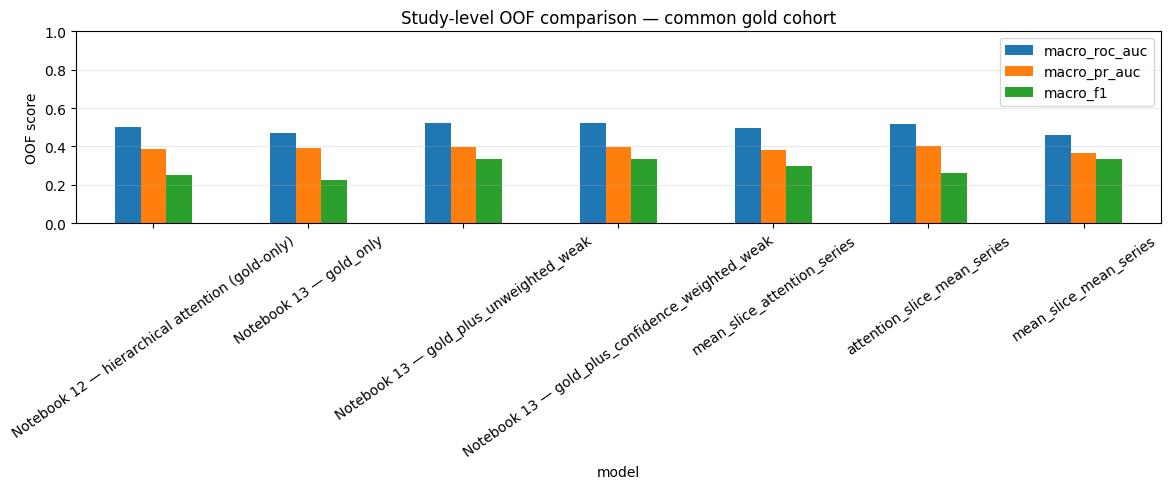

,model,macro_roc_auc,macro_pr_auc,macro_f1,micro_f1,hamming_loss
0,Notebook 12 — hierarchical attention (gold-only),0.501211,0.385464,0.250811,0.341969,0.364943
1,Notebook 13 — gold_only,0.470951,0.392358,0.226700,0.330484,0.337644
2,Notebook 13 — gold_plus_unweighted_weak,0.520096,0.396903,0.333171,0.480144,0.413793
3,Notebook 13 — gold_plus_confidence_weighted_weak,0.520096,0.396903,0.333171,0.480144,0.413793
4,mean_slice_attention_series,0.498008,0.383255,0.296774,0.397590,0.431034
5,attention_slice_mean_series,0.515732,0.401569,0.263458,0.395745,0.408046
6,mean_slice_mean_series,0.457205,0.365604,0.333024,0.430189,0.433908


In [19]:
def evaluate_probs(y_true, y_prob):
    pred = (y_prob >= THRESHOLD).astype(int)
    auc, ap, f1 = [], [], []

    for j in range(y_true.shape[1]):
        yt = y_true[:, j]

        auc.append(
            roc_auc_score(yt, y_prob[:, j])
            if len(np.unique(yt)) == 2 else np.nan
        )

        ap.append(
            average_precision_score(yt, y_prob[:, j])
            if len(np.unique(yt)) == 2 else np.nan
        )

        f1.append(
            f1_score(yt, pred[:, j], zero_division=0)
        )

    return {
        "macro_roc_auc": float(np.nanmean(auc)),
        "macro_pr_auc": float(np.nanmean(ap)),
        "macro_f1": float(np.mean(f1)),
        "micro_f1": float(
            f1_score(
                y_true.ravel(),
                pred.ravel(),
                zero_division=0
            )
        ),
        "hamming_loss": float(hamming_loss(y_true, pred))
    }


comparison = [{
    "model": "Notebook 12 — hierarchical attention (gold-only)",
    **evaluate_probs(Y, P12)
}]


# Notebook 13: Compare all three supervision modes
if weak_oof is not None:

    weak_oof.columns = weak_oof.columns.astype(str).str.strip()

    required_cols = {"StudyInstanceUID", "mode"}

    for c in LABEL_COLS:
        required_cols.add(f"{c}_prob")

    missing = required_cols - set(weak_oof.columns)

    if missing:
        raise ValueError(
            f"Notebook 13 OOF missing columns: {sorted(missing)}"
        )

    weak_oof["StudyInstanceUID"] = (
        weak_oof["StudyInstanceUID"].astype(str)
    )

    expected_modes = [
        "gold_only",
        "gold_plus_unweighted_weak",
        "gold_plus_confidence_weighted_weak"
    ]

    actual_modes = set(weak_oof["mode"].dropna().unique())

    if actual_modes != set(expected_modes):
        raise ValueError(
            f"Unexpected Notebook 13 modes: {actual_modes}"
        )

    for mode_name in expected_modes:

        # Use bracket notation: never use weak_oof.mode
        part = weak_oof[
            weak_oof["mode"] == mode_name
        ].copy()

        if part["StudyInstanceUID"].duplicated().any():
            raise ValueError(
                f"Duplicate study predictions for {mode_name}"
            )

        part = part.set_index("StudyInstanceUID")

        missing_ids = set(GOLD_IDS) - set(part.index)

        if missing_ids:
            raise ValueError(
                f"Missing {len(missing_ids)} gold studies "
                f"in Notebook 13 mode {mode_name}"
            )

        part = part.loc[GOLD_IDS]

        p = part[prob_cols].to_numpy(dtype=float)

        if p.shape != Y.shape:
            raise ValueError(
                f"Prediction shape mismatch for {mode_name}: "
                f"{p.shape} versus {Y.shape}"
            )

        if not np.isfinite(p).all():
            raise ValueError(
                f"Non-finite predictions in {mode_name}"
            )

        comparison.append({
            "model": f"Notebook 13 — {mode_name}",
            **evaluate_probs(Y, p)
        })


# Ablation predictions
if not ablation_predictions.empty:

    ablation_predictions.columns = (
        ablation_predictions.columns.astype(str).str.strip()
    )

    for variant_name in VARIANTS:

        # Use explicit column access
        part = ablation_predictions[
            ablation_predictions["variant"] == variant_name
        ].copy()

        if part.empty:
            print(f"WARNING: No predictions found for {variant_name}")
            continue

        part["StudyInstanceUID"] = (
            part["StudyInstanceUID"].astype(str)
        )

        if part["StudyInstanceUID"].duplicated().any():
            raise ValueError(
                f"Duplicate study predictions for {variant_name}"
            )

        part = part.set_index("StudyInstanceUID")

        missing_ids = set(GOLD_IDS) - set(part.index)

        if missing_ids:
            raise ValueError(
                f"Missing {len(missing_ids)} gold studies "
                f"for ablation {variant_name}"
            )

        part = part.loc[GOLD_IDS]

        p = part[prob_cols].to_numpy(dtype=float)

        if p.shape != Y.shape or not np.isfinite(p).all():
            raise ValueError(
                f"Invalid predictions for ablation {variant_name}"
            )

        comparison.append({
            "model": variant_name,
            **evaluate_probs(Y, p)
        })


# Save comparison
comparison_df = pd.DataFrame(comparison)

comparison_df.to_csv(
    OUTPUT_DIR / "16_pooling_ablation_comparison.csv",
    index=False
)

# Plot comparison
fig, ax = plt.subplots(figsize=(12, 5))

comparison_df.set_index("model")[
    ["macro_roc_auc", "macro_pr_auc", "macro_f1"]
].plot(kind="bar", ax=ax)

ax.set_ylim(0, 1)
ax.set_ylabel("OOF score")
ax.set_title(
    "Study-level OOF comparison — common gold cohort"
)
ax.tick_params(axis="x", rotation=35)
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "16_model_comparison.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

display(comparison_df)

## 9. Robustness checks using the original Notebook 12 fold checkpoints

Two controlled perturbations are applied to the MRI-derived embedding bags for each held-out study: small Gaussian feature noise (5% of the global embedding standard deviation) and deterministic random removal of 10% of 2.5D instances per series (retaining at least one instance). These are sensitivity checks, not substitutes for external validation.

In [20]:
class GatedAttentionPoolNB12(nn.Module):

    def __init__(
        self,
        input_dim=EMBED_DIM,
        attention_dim=ATTENTION_DIM
    ):
        super().__init__()

        self.norm = nn.LayerNorm(input_dim)

        self.attention_v = nn.Linear(
            input_dim, attention_dim
        )

        self.attention_u = nn.Linear(
            input_dim, attention_dim
        )

        self.attention_w = nn.Linear(
            attention_dim, 1, bias=False
        )

    def forward(self, x):

        z = self.norm(x)

        g = (
            torch.tanh(self.attention_v(z))
            * torch.sigmoid(self.attention_u(z))
        )

        w = torch.softmax(
            self.attention_w(g).squeeze(-1),
            dim=0
        )

        pooled = (w.unsqueeze(-1) * z).sum(0)

        return pooled, w


class HierarchicalDINOv2MILNB12(nn.Module):

    def __init__(self):
        super().__init__()

        self.slice_attention = GatedAttentionPoolNB12()
        self.series_attention = GatedAttentionPoolNB12()

        self.classifier = nn.Sequential(
            nn.LayerNorm(EMBED_DIM),
            nn.Linear(EMBED_DIM, HIDDEN_DIM),
            nn.GELU(),
            nn.Dropout(DROPOUT),
            nn.Linear(HIDDEN_DIM, NUM_CLASSES)
        )

    def forward(self, bags):

        series_vectors = []

        for x in bags:
            pooled, _ = self.slice_attention(x)
            series_vectors.append(pooled)

        study_vector, _ = self.series_attention(
            torch.stack(series_vectors, dim=0)
        )

        return self.classifier(study_vector)


def load_nb12(fold):

    try:
        ck = torch.load(
            NB12_CHECKPOINTS[fold],
            map_location="cpu",
            weights_only=False
        )

    except TypeError:
        ck = torch.load(
            NB12_CHECKPOINTS[fold],
            map_location="cpu"
        )

    if ck.get("label_cols") != LABEL_COLS:
        raise ValueError(
            f"Notebook 12 checkpoint label order mismatch "
            f"in fold {fold}"
        )

    model = HierarchicalDINOv2MILNB12().to(DEVICE)

    model.load_state_dict(
        ck["model_state_dict"],
        strict=True
    )

    model.eval()

    return model


# Check embedding data before perturbation experiments
embedding_array = np.asarray(embeddings)

if embedding_array.size == 0:
    raise ValueError("DINOv2 embedding array is empty.")

if not np.isfinite(
    embedding_array[:min(len(embedding_array), 5000)]
).all():
    raise ValueError("Non-finite values detected in embeddings.")

embedding_std = float(
    embedding_array[
        :min(len(embedding_array), 5000)
    ].astype(np.float32).std()
)

if not np.isfinite(embedding_std) or embedding_std <= 0:
    raise ValueError("Invalid embedding standard deviation.")

noise_std = NOISE_FRACTION * embedding_std

robust_rows = []


for fold in range(N_FOLDS):

    print(f"Running robustness checks: fold {fold}")

    model = load_nb12(fold)

    heldout = sorted([
        s for s in GOLD_IDS
        if FOLD_BY_STUDY[s] == fold
    ])

    for i, sid in enumerate(heldout):

        experiment_seed = SEED + fold * 100 + i

        # Original prediction
        base_bags = get_study_tensors(
            sid,
            seed=experiment_seed
        )

        with torch.no_grad():
            p_base = torch.sigmoid(
                model(base_bags)
            ).cpu().numpy()

        # Embedding noise perturbation
        noise_bags = get_study_tensors(
            sid,
            noise_std=noise_std,
            seed=experiment_seed
        )

        with torch.no_grad():
            p_noise = torch.sigmoid(
                model(noise_bags)
            ).cpu().numpy()

        # Random instance removal
        drop_bags = get_study_tensors(
            sid,
            drop_fraction=RANDOM_INSTANCE_DROP_FRACTION,
            seed=experiment_seed
        )

        with torch.no_grad():
            p_drop = torch.sigmoid(
                model(drop_bags)
            ).cpu().numpy()

        row = {
            "StudyInstanceUID": sid,
            "fold": fold,
            "noise_std": noise_std,
            "instance_drop_fraction":
                RANDOM_INSTANCE_DROP_FRACTION,

            "mean_abs_change_noise": float(
                np.mean(np.abs(p_base - p_noise))
            ),

            "mean_abs_change_random_instance_drop": float(
                np.mean(np.abs(p_base - p_drop))
            )
        }

        for j, c in enumerate(LABEL_COLS):

            row[f"{c}_base"] = float(p_base[j])
            row[f"{c}_noise"] = float(p_noise[j])
            row[f"{c}_drop"] = float(p_drop[j])

        robust_rows.append(row)

    del model

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# Save individual robustness results
robust_df = pd.DataFrame(robust_rows)

if robust_df.empty:
    raise ValueError(
        "No robustness results generated. "
        "Check the gold-study folds and checkpoint paths."
    )

robust_df.to_csv(
    OUTPUT_DIR / "16_robustness_checks.csv",
    index=False
)


# Summarize perturbation effects
robust_summary = pd.DataFrame([

    {
        "perturbation": "embedding_noise",

        "mean_abs_probability_change":
            robust_df["mean_abs_change_noise"].mean(),

        "median_abs_probability_change":
            robust_df["mean_abs_change_noise"].median()
    },

    {
        "perturbation": "random_2p5d_instance_removal",

        "mean_abs_probability_change":
            robust_df[
                "mean_abs_change_random_instance_drop"
            ].mean(),

        "median_abs_probability_change":
            robust_df[
                "mean_abs_change_random_instance_drop"
            ].median()
    }

])

robust_summary.to_csv(
    OUTPUT_DIR / "16_robustness_summary.csv",
    index=False
)

display(robust_summary)

print("Robustness experiments completed.")

Running robustness checks: fold 0
Running robustness checks: fold 1
Running robustness checks: fold 2
Running robustness checks: fold 3
Running robustness checks: fold 4


,perturbation,mean_abs_probability_change,median_abs_probability_change
0,embedding_noise,0.001305,0.001276
1,random_2p5d_instance_removal,0.003234,0.000722


Robustness experiments completed.


## 10. Final artifact audit and limitations

Report the full comparison table, not only the best row. With 58 gold studies, fold-level estimates are descriptive and may be unstable for rare findings. The model uses report-derived supervision only in Notebook 13 training; all OOF predictions here are MRI-model outputs.

In [21]:
expected=["16_label_level_error_taxonomy.csv","16_study_error_summary.csv","16_error_counts_by_label.csv","16_oof_per_label_metrics.csv","16_pooling_ablation_comparison.csv","16_model_comparison.png","16_robustness_checks.csv","16_robustness_summary.csv"]
if RUN_POOLING_ABLATIONS: expected.append("16_pooling_ablation_oof_predictions.csv")
missing=[name for name in expected if not (OUTPUT_DIR/name).exists()]
audit={"notebook":"16_ablation_error.ipynb","n_gold_studies":len(GOLD_IDS),"n_folds":N_FOLDS,"pooling_ablation_variants":list(VARIANTS) if RUN_POOLING_ABLATIONS else [],
       "ablation_epoch_policy":"per-fold best_epoch transferred from Notebook 12; fixed for each ablation",
       "weak_supervision_oof_available":NB13_OOF_PATH is not None,"notebook14_metrics_available":NB14_METRICS_PATH is not None,
       "embedding_noise_std":noise_std,"random_instance_drop_fraction":RANDOM_INSTANCE_DROP_FRACTION,"missing_artifacts":missing}
with open(OUTPUT_DIR/"run_summary.json","w") as f: json.dump(audit,f,indent=2)
print(json.dumps(audit,indent=2))
if missing: raise RuntimeError("Notebook 16 missing expected artifacts: "+", ".join(missing))
print("NOTEBOOK 16 COMPLETED.")

{
  "notebook": "16_ablation_error.ipynb",
  "n_gold_studies": 58,
  "n_folds": 5,
  "pooling_ablation_variants": [
    "mean_slice_attention_series",
    "attention_slice_mean_series",
    "mean_slice_mean_series"
  ],
  "ablation_epoch_policy": "per-fold best_epoch transferred from Notebook 12; fixed for each ablation",
  "weak_supervision_oof_available": true,
  "notebook14_metrics_available": true,
  "embedding_noise_std": 0.12153140306472779,
  "random_instance_drop_fraction": 0.1,
  "missing_artifacts": []
}
NOTEBOOK 16 COMPLETED.
